## Lab 4: Diffusion Models for Anomaly Detection (Tabular Data)

**Alejandro Lancho Serrano, Vanessa Gómez Verdejo, Pablo Martínez Olmos, Emilio Parrado Hernández**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='http://www.tsc.uc3m.es/~emipar/BBVA/INTRO/img/logo_uc3m_foot.jpg' width=400 />

In this lab, you will build an **unsupervised anomaly detection system** for credit card fraud using **diffusion models**, and compare it against classical and neural baselines.

You are given:
- basic library imports,
- the dataset.

From this point on, **you are responsible for designing, implementing, and evaluating the models**.

---

## Objectives

By the end of this lab, you should be able to:

- Apply **diffusion models** to tabular data.
- Use **denoising difficulty** as an anomaly score.
- Evaluate anomaly detectors under **extreme class imbalance**.
- Select and justify **decision thresholds**.
- Compare modern generative models with **strong baselines**.

---

## Tasks

### 1. Exploratory Data Analysis (EDA)
- Load the dataset and inspect the class imbalance.
- Visualize at least one informative feature (e.g., `Amount`) by class.
- Explain why **AUPRC** is more informative than accuracy in this setting.

*Expected outputs:* brief plots + 2–3 sentences of interpretation.

---

### 2. Diffusion Model for Tabular Data
- Implement a **forward diffusion process** for tabular vectors:
  - Choose a noise schedule (linear or cosine).
  - Implement the noising operation $ x_t $.
- Build a **denoising neural network** (MLP):
  - Input: noised data + time embedding.
  - Output: predicted noise.
- Train the model **only on normal transactions**.

*Expected outputs:* training loss curve + explanation of design choices.

---

### 3. Diffusion-Based Anomaly Scoring
Implement **at least one** of the following anomaly scores:
- **Residual-based score:** noise prediction error.
- **Reconstruction-based score:** error in reconstructed $ \hat{x}_0 $.

- Aggregate scores over multiple random timesteps.
- Explain why stochastic averaging is useful.

*Expected outputs:* function to compute scores + short explanation.

---

### 4. Evaluation (No Threshold Yet)
- Evaluate diffusion scores on **validation and test sets** using:
  - AUROC
  - AUPRC
- Plot Precision–Recall curves.
- Compare results to the random baseline.

*Expected outputs:* metrics + PR curves + interpretation.

---

### 5. Threshold Selection
Using the **validation set only**:
- Implement at least two thresholding strategies:
  - target precision or recall,
  - max-F1.
- Visualize confusion matrices for different thresholds.
- Discuss the trade-off between false positives and false negatives.

*Expected outputs:* confusion matrices + discussion.

---

### 6. Final Test Evaluation
- Fix **one threshold** chosen on validation.
- Apply it **once** to the test set.
- Report:
  - confusion matrix,
  - precision, recall, FPR, F1.

*Expected outputs:* final test results + interpretation.

---

### 7. Baseline Comparisons
Implement and evaluate **at least two baselines** (e.g.):
- **Isolation Forest**
- **Autoencoder**

Requirements:
- Train on normal samples only.
- Use the same evaluation metrics and splits.
- Produce comparable anomaly scores.

*Expected outputs:* AUROC/AUPRC on test set + PR curves.

---

### 8. Comparative Analysis
- Summarize results for:
  - Diffusion model
  - Isolation Forest
  - Autoencoder

  

*Expected outputs* must include answers to:
  - Which method performs best here?
  - Why might that be the case?
  - What does diffusion offer beyond raw performance?


## Setting Things Up <a id="setup"></a>

In [1]:
# ======================================================
# Setup: imports, device, and reproducibility
# ======================================================

# --- Standard library ---
import os
import math
import random
import time
import json
import subprocess
import sys
from pathlib import Path
from typing import Tuple

# --- Numerical & data handling ---
import numpy as np
import pandas as pd

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- PyTorch ---
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# --- Lightning ---
import pytorch_lightning as pl
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor

# --- Scikit-learn ---
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    f1_score,
    confusion_matrix,
)
from sklearn.ensemble import IsolationForest

# --- Device setup ---
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Using device:", device)

# --- Reproducibility ---
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

Using device: cpu


## Dataset <a id="data"></a>

We use the **Credit Card Fraud Detection** dataset introduced by Dal Pozzolo et al. (2015),  
containing **284,807 transactions** with a severe class imbalance  
(**fraud ≈ 0.17%**).

The dataset consists of:
- anonymized PCA features (`V1`–`V28`),
- transaction `Amount`,
- binary label `Class` (0 = normal, 1 = fraud).

---

### Automatic download options

To make the lab reproducible across environments, the notebook attempts to obtain  
`creditcard.csv` using the following **fallback chain**:

1. **Local file (fastest)**  
   - If `./data/creditcard.csv` already exists, it is loaded directly.

2. **Kaggle API (optional)**  
   - Requires a Kaggle API token at `~/.kaggle/kaggle.json`.  
   - You can generate this from *Kaggle → Account → Create API Token*.

3. **OpenML mirror (no credentials)**  
   - Downloads the same dataset via OpenML (dataset ID 1597).  
   - May be blocked on some institutional networks.

4. **Direct HTTP mirror**  
   - Downloads the dataset from a public mirror.  
   - Requires no credentials and works in most environments.

The dataset is always saved locally to: `./data/creditcard.csv`

---

### Manual fallback

If all automatic methods fail (e.g., no internet access),  
download `creditcard.csv` manually and place it in `./data/`, then re-run the notebook.

---

> **Note:**  
> All experiments in this lab use the same dataset splits and evaluation protocol,  
> regardless of which download method is used.

In [2]:
# ======================================================
# Downloader + Loader for creditcard.csv
# Priority:
#   1) Local file
#   2) Direct HTTP (no extra packages or credentials)
#   3) Kaggle (if credentials exist)
#   4) OpenML (if installed)
# ======================================================

DATA_DIR = Path("./data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "creditcard.csv"


# ------------------------------------------------------
# Utility helpers
# ------------------------------------------------------

def have_kaggle_creds():
    kaggle_json = Path.home() / ".kaggle" / "kaggle.json"
    return kaggle_json.exists()




# ------------------------------------------------------
# Kaggle download
# ------------------------------------------------------

def download_via_kaggle():
    """
    Requires:
      - ~/.kaggle/kaggle.json present (Kaggle API credentials)
      - Internet access
    """
    print("Attempting Kaggle download...")

    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    os.chmod(kaggle_dir, 0o700)

    kj = kaggle_dir / "kaggle.json"
    if not kj.exists():
        print("No kaggle.json found at ~/.kaggle/kaggle.json")
        return False
    os.chmod(kj, 0o600)

    try:
        import kaggle  # Optional dependency.

        subprocess.check_call([
            sys.executable, "-m", "kaggle", "datasets", "download",
            "-d", "mlg-ulb/creditcardfraud",
            "-p", str(DATA_DIR),
            "-f", "creditcard.csv"
        ])

        if CSV_PATH.exists():
            print(f"Found {CSV_PATH}")
            return True

        # Fallback: extract from zip if needed
        import zipfile
        for z in DATA_DIR.glob("*.zip"):
            with zipfile.ZipFile(z, "r") as zf:
                if "creditcard.csv" in zf.namelist():
                    zf.extract("creditcard.csv", DATA_DIR)
                    print(f"Extracted creditcard.csv from {z}")
                    return True

        print("Kaggle download did not produce creditcard.csv")
        return False

    except Exception as e:
        print("Kaggle download failed:", e)
        return False


# ------------------------------------------------------
# OpenML download
# ------------------------------------------------------

def download_via_openml():
    """
    Uses openml-python to fetch the dataset.
    Often blocked on institutional networks.
    """
    print("Attempting OpenML download...")
    try:
        import openml  # Optional dependency.

        # OpenML ID commonly associated with creditcard fraud
        ds = openml.datasets.get_dataset(1597)

        X, y, categorical, attribute_names = ds.get_data(
            dataset_format="dataframe",
            target=ds.default_target_attribute
        )

        df = X.copy()
        df["Class"] = y
        df.to_csv(CSV_PATH, index=False)

        print(f"Saved {CSV_PATH} via OpenML")
        return True

    except Exception as e:
        print("OpenML download failed:", e)
        return False


# ------------------------------------------------------
# Direct HTTP fallback (RECOMMENDED)
# ------------------------------------------------------

def download_via_http():
    """
    Direct public mirror.
    No credentials, works in most environments.
    """
    print("Attempting direct HTTP download...")
    url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

    try:
        df = pd.read_csv(url)
        df.to_csv(CSV_PATH, index=False)
        print(f"Saved {CSV_PATH} via HTTP")
        return True
    except Exception as e:
        print("HTTP download failed:", e)
        return False


# ------------------------------------------------------
# Unified loader
# ------------------------------------------------------

def load_creditcard_csv():
    if CSV_PATH.exists():
        print(f"Loading local {CSV_PATH}")
        return pd.read_csv(CSV_PATH)

    if download_via_http():
        return pd.read_csv(CSV_PATH)

    if have_kaggle_creds() and download_via_kaggle():
        return pd.read_csv(CSV_PATH)

    if download_via_openml():
        return pd.read_csv(CSV_PATH)

    raise FileNotFoundError(
        "Could not obtain creditcard.csv.\n"
        "Please place the file manually at ./data/creditcard.csv and re-run."
    )


# ------------------------------------------------------
# Execute
# ------------------------------------------------------

df = load_creditcard_csv()
print("Dataset shape:", df.shape)
print("First columns:", df.columns.tolist()[:10], "...")
print("Class distribution:", df["Class"].value_counts().to_dict())

Attempting direct HTTP download...
Saved data\creditcard.csv via HTTP
Dataset shape: (284807, 31)
First columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9'] ...
Class distribution: {0: 284315, 1: 492}


## Tasks

### 1. Exploratory Data Analysis (EDA)
- Load the dataset and inspect the class imbalance.
- Visualize at least one informative feature (e.g., `Amount`) by class.
- Explain why **AUPRC** is more informative than accuracy in this setting.

*Expected outputs:* brief plots + 2–3 sentences of interpretation.


In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Class mean: 0.17%


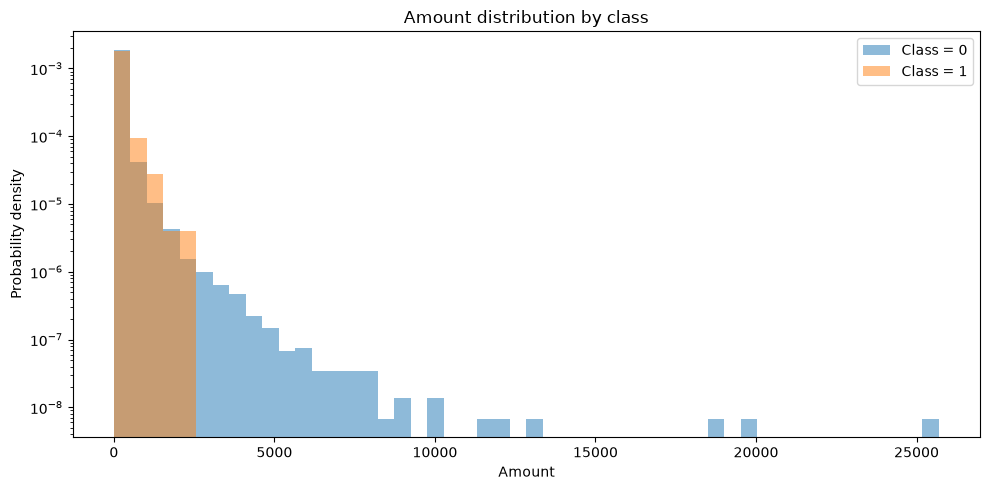

In [4]:
print(f"Class mean: {df['Class'].mean():.2%}")

# Compute shared bin edges from both classes.
bins = np.histogram_bin_edges(df["Amount"].dropna(), bins=50)

fig, ax = plt.subplots(figsize=(10, 5))
for label in (0, 1):
    ax.hist(
        df.loc[df["Class"] == label, "Amount"].dropna(),
        bins=bins,
        density=True,
        alpha=0.5,
        label=f"Class = {label}",
    )
ax.set_xlabel("Amount")
ax.set_ylabel("Probability density")
ax.set_yscale("log")
ax.set_title("Amount distribution by class")
ax.legend()
plt.tight_layout()
plt.show()


Data normalization.

In [5]:
# Separate features from the class labels.
X = df.drop(columns="Class").to_numpy()
y = df["Class"].to_numpy()

# Standardize each feature to zero mean and unit variance.
scaler = StandardScaler()
X = scaler.fit_transform(X)


### 2. Diffusion Model for Tabular Data
- Implement a **forward diffusion process** for tabular vectors:
  - Choose a noise schedule (linear or cosine).
  - Implement the noising operation $ x_t $.
- Build a **denoising neural network** (MLP):
  - Input: noised data + time embedding.
  - Output: predicted noise.
- Train the model **only on normal transactions**.

*Expected outputs:* training loss curve + explanation of design choices.

In [6]:
# Hyperparameters

# Diffusion hyperparameters
timesteps = 500  # Number of timesteps for the forward and reverse diffusion processes
beta1 = 1e-4     # Starting value for the beta schedule (variance of noise added in the forward process)
beta2 = 0.02     # Final value for the beta schedule

# Training hyperparameters
batch_size = 100  # Number of samples per training batch
n_epoch = 32      # Number of training epochs
lrate = 1e-3      # Initial learning rate for the optimizer

# ----- DDPM noise schedule (fixed, no learning) -----

# Linearly spaced beta_t from beta1 to beta2.
# Index 0 is a clean-data sentinel; diffusion steps are t = 1, ..., T.
b_t = torch.zeros(timesteps + 1, device=device)
b_t[1:] = (beta2 - beta1) * torch.linspace(0, 1, timesteps, device=device) + beta1

# Per-step signal factor alpha_t = 1 - beta_t.
alpha_t = 1.0 - b_t

# Cumulative product abar_t = prod_{s<=t} alpha_s, in log-space for numerical stability.
# abar_t is the signal weight in the one-shot identity x_t = sqrt(abar_t) x0 + sqrt(1-abar_t) eps.
ab_t = torch.cumsum(alpha_t.log(), dim=0).exp()


ab_t[0] = 1.0  # abar_0 = 1: no noise at the start

# ----- Posterior weights, precomputed from the schedule alone -----
# Exact reverse step given x0:  q(x_{t-1}|x_t,x0) = N(c1(t) x_t + c2(t) x0, beta_tilde_t * I).
# Shift abar_t to obtain the previous cumulative signal factor.
ab_prev = torch.cat([ab_t[:1], ab_t[:-1]])                   # abar_{t-1}
one_minus_ab = 1.0 - ab_t
c1_t = alpha_t.sqrt() * (1.0 - ab_prev) / one_minus_ab        # trust in current state x_t
c2_t = ab_prev.sqrt() * b_t / one_minus_ab                    # trust in clean target x0
beta_tilde_t = (1.0 - ab_prev) / one_minus_ab * b_t           # exact posterior variance
# index 0 is never used at sampling time (steps run t = T, ..., 1); zero out the 1/0 there
c1_t[0] = 0.0
c2_t[0] = 0.0
beta_tilde_t[0] = 0.0



In [ ]:
class ErrorPredNN(torch.nn.Module):
    """Predict diffusion noise with the same shape as the input features."""

    def __init__(self, num_features, num_hidden_layers, hidden_size):
        super().__init__()
        if num_features < 1 or num_hidden_layers < 0 or hidden_size < 1:
            raise ValueError("Require positive feature/hidden sizes and nonnegative layer count.")
        
        layers = []
        # Add one input for the normalized diffusion timestep.
        input_size = num_features + 1
        for _ in range(num_hidden_layers):
            layers.extend([
                torch.nn.Linear(input_size, hidden_size),
                torch.nn.ReLU(),
            ])
            input_size = hidden_size
        # Predict one noise value per feature; noise can have either sign.
        layers.append(torch.nn.Linear(input_size, num_features))
        self.all_layers = torch.nn.Sequential(*layers)

    def forward(self, x, t):
        # x: (batch, num_features); t: scalar, (batch,), or (batch, 1).
        x = torch.flatten(x, start_dim=1)
        t = torch.as_tensor(t, device=x.device, dtype=x.dtype)
        if t.numel() == 1:
            t = t.reshape(1, 1).expand(x.shape[0], 1)
        else:
            t = t.reshape(x.shape[0], 1)
        inputs = torch.cat([x, t, dim=1)
        return self.all_layers(inputs)




In [20]:
class LitDifussionModel(pl.LightningModule):
    def __init__(self, num_features, num_hidden_layers, hidden_size ,timesteps = 500, beta1 = 1e-4, beta2 = 0.02, lr = 1e-3):
                 
        super().__init__()

        self.save_hyperparameters(ignore=['model', 'loss', 'accuracy'])  # logs hyperparameters automatically

        self.compute_diffusion_params()

        self.model = ErrorPredNN(num_features, num_hidden_layers, hidden_size)

        self.timesteps = timesteps
        self.beta1 = beta1
        self.beta2 = beta2
        self.lr = lr

    def compute_diffusion_params(self):

        # ----- DDPM noise schedule (fixed, no learning) -----

        # Linearly spaced beta_t from beta1 to beta2.
        # Index 0 is a clean-data sentinel; diffusion steps are t = 1, ..., T.
        self.b_t = torch.zeros(timesteps + 1, device=device)
        b_t[1:] = (beta2 - beta1) * torch.linspace(0, 1, timesteps, device=device) + beta1

        # Per-step signal factor alpha_t = 1 - beta_t.
        self.alpha_t = 1.0 - b_t

        # Cumulative product abar_t = prod_{s<=t} alpha_s, in log-space for numerical stability.
        # abar_t is the signal weight in the one-shot identity x_t = sqrt(abar_t) x0 + sqrt(1-abar_t) eps.
        self.ab_t = torch.cumsum(alpha_t.log(), dim=0).exp()


        ab_t[0] = 1.0  # abar_0 = 1: no noise at the start

        # ----- Posterior weights, precomputed from the schedule alone -----
        # Exact reverse step given x0:  q(x_{t-1}|x_t,x0) = N(c1(t) x_t + c2(t) x0, beta_tilde_t * I).
        # Shift abar_t to obtain the previous cumulative signal factor.
        ab_prev = torch.cat([ab_t[:1], ab_t[:-1]])                   # abar_{t-1}
        one_minus_ab = 1.0 - ab_t
        self.c1_t = alpha_t.sqrt() * (1.0 - ab_prev) / one_minus_ab        # trust in current state x_t
        self.c2_t = ab_prev.sqrt() * b_t / one_minus_ab                    # trust in clean target x0
        beta_tilde_t = (1.0 - ab_prev) / one_minus_ab * b_t           # exact posterior variance
        # index 0 is never used at sampling time (steps run t = T, ..., 1); zero out the 1/0 there
        c1_t[0] = 0.0
        c2_t[0] = 0.0
        beta_tilde_t[0] = 0.0

        

    # Forward process in one shot: corrupt a clean tabular vector x0 to noise level t.
    def perturb_input(x0, t, eps):
        """
        Apply the forward identity  x_t = sqrt(abar_t) x0 + sqrt(1 - abar_t) eps.

        Parameters
        ----------
        x0  : clean tabular vector(s), the data we start from.
        t   : time step(s); selects how much signal survives via abar_t.
        eps : Gaussian noise of the same shape as x0 (the eps the network learns to predict).

        Returns
        -------
        x_t : the noised tabular vector at level t.
        """
        # [t, None] gives one coefficient per row, broadcasting over (B, features).
        signal = ab_t[t, None].sqrt() * x0             # sqrt(abar_t) * x0
        noise  = (1.0 - ab_t[t, None]).sqrt() * eps    # sqrt(1 - abar_t) * eps
        return signal + noise

    def forward(self, x, t):
        return self.model(x, t)

    def _shared_step(self, batch):

        x0 = batch
        t = torch.randint(1, self.model.num_timesteps + 1, (x0.shape[0],), device=x0.device)
        noise = torch.randn_like(x0)
        x_noise = self.perturb_input(x0, t / self.num_timesteps, noise)

        noise_estimate = self(x_noise, t)

        loss = F.mse_loss(noise_estimate, noise)
        acc = F.mse_loss(noise_estimate, noise)
  
        return loss, acc, noise_estimate, noise

    def training_step(self, batch, batch_idx):
        loss, acc, noise_estimate, noise = self._shared_step(batch)
        self.log('loss.train', loss, on_epoch=True, on_step=False, prog_bar=False)
        self.log('score.train', acc, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def validation_step(self, batch, batch_idx):
        loss, acc, ys_estimate, ys = self._shared_step(batch)
        self.log('loss.valid', loss, on_epoch=True, on_step=False, prog_bar=False)
        self.log('score.valid', acc, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def test_step(self, batch, batch_idx):
        loss, acc, ys_estimate, ys = self._shared_step(batch)
        self.log('loss.test', loss, on_epoch=True, on_step=False, prog_bar=False)
        self.log('score.test', acc, on_epoch=True, on_step=False, prog_bar=False)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

In [21]:
num_epochs = 50



diff_model = LitDifussionModel(num_features= 30, num_hidden_layers= 3, hidden_size= 64, 
        timesteps= 500, beta1= 1e-4, beta2= 0.02, lr = 1e-3)

logger = CSVLogger(
    save_dir="lightning_logs",
    name="MLP",
    version="fixed"
);

'''

trainer =  pl.Trainer(max_epochs=num_epochs,
    log_every_n_steps=1,
    deterministic=True,     # aim for reproducibility where possible
    accelerator="auto",     # use GPU if available
    devices="auto",
    logger=logger)

train_data_loader = DataLoader(train_data, batch_size=64, shuffle=False)
valid_data_loader = DataLoader(val_data, batch_size=64, shuffle=False)
test_data_loader = DataLoader(test_data, batch_size=64, shuffle=False)

trainer.fit(lit_model, train_dataloaders=train_data_loader, val_dataloaders=valid_data_loader)
'''

'\n\ntrainer =  pl.Trainer(max_epochs=num_epochs,\n    log_every_n_steps=1,\n    deterministic=True,     # aim for reproducibility where possible\n    accelerator="auto",     # use GPU if available\n    devices="auto",\n    logger=logger)\n\ntrain_data_loader = DataLoader(train_data, batch_size=64, shuffle=False)\nvalid_data_loader = DataLoader(val_data, batch_size=64, shuffle=False)\ntest_data_loader = DataLoader(test_data, batch_size=64, shuffle=False)\n\ntrainer.fit(lit_model, train_dataloaders=train_data_loader, val_dataloaders=valid_data_loader)\n'

In [22]:
diff_model.ab_t

tensor([1.0000, 0.9999, 0.9998, 0.9996, 0.9994, 0.9991, 0.9988, 0.9985, 0.9981,
        0.9977, 0.9972, 0.9967, 0.9962, 0.9956, 0.9950, 0.9943, 0.9936, 0.9929,
        0.9921, 0.9913, 0.9905, 0.9896, 0.9886, 0.9877, 0.9867, 0.9856, 0.9846,
        0.9834, 0.9823, 0.9811, 0.9798, 0.9786, 0.9773, 0.9759, 0.9745, 0.9731,
        0.9717, 0.9702, 0.9686, 0.9671, 0.9655, 0.9638, 0.9622, 0.9605, 0.9587,
        0.9569, 0.9551, 0.9533, 0.9514, 0.9495, 0.9475, 0.9456, 0.9435, 0.9415,
        0.9394, 0.9373, 0.9351, 0.9330, 0.9307, 0.9285, 0.9262, 0.9239, 0.9216,
        0.9192, 0.9168, 0.9144, 0.9119, 0.9094, 0.9069, 0.9043, 0.9018, 0.8992,
        0.8965, 0.8939, 0.8912, 0.8884, 0.8857, 0.8829, 0.8801, 0.8773, 0.8744,
        0.8716, 0.8687, 0.8657, 0.8628, 0.8598, 0.8568, 0.8538, 0.8507, 0.8477,
        0.8446, 0.8415, 0.8383, 0.8352, 0.8320, 0.8288, 0.8256, 0.8223, 0.8190,
        0.8158, 0.8125, 0.8091, 0.8058, 0.8024, 0.7991, 0.7957, 0.7923, 0.7888,
        0.7854, 0.7819, 0.7784, 0.7750, 